# Which LLM wrote this text? Authorship attribution with TF-IDF baselines

**Task.** Given a text, predict which of 18 language models generated it.
The training set contains 2,699 texts: ~150 prompts, each answered by every one of the 18 models.
The test set has no `model` column. On Kaggle the notebook is re-run on a **hidden** test set, so everything (fitting and prediction) must run from `train.csv` and whatever `test.csv` is present at run time.

**Approach.** TF-IDF features (word n-grams / character n-grams) + multinomial logistic regression.

**Evaluation protocol.**
- Metric: balanced accuracy (the chance level with 18 classes is 1/18 ≈ 0.056).
- A validation set is held out from the labelled data, split **by prompt** so that no prompt appears on both sides.
- 5-fold grouped cross-validation is run on the training part only.
- The train vs. validation gap is used to diagnose overfitting.

In [2]:
import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import balanced_accuracy_score
from sklearn.model_selection import StratifiedGroupKFold, cross_val_score
from sklearn.pipeline import Pipeline

SEED = 42

## 1. Data

In [3]:
from pathlib import Path

# On Kaggle the data lives under /kaggle/input; on Colab / locally we fall back to ./data
kaggle_train = next(Path("/kaggle/input").rglob("train.csv"), None) if Path("/kaggle/input").exists() else None
DATA_DIR = kaggle_train.parent if kaggle_train else Path("data")
OUTPUT_DIR = Path("/kaggle/working") if Path("/kaggle/working").exists() else Path(".")

train_df = pd.read_csv(DATA_DIR / "train.csv")  # columns: id, prompt_id, text, model
test_df = pd.read_csv(DATA_DIR / "test.csv")    # same columns without `model`

In [4]:
train_df.head()

,id,prompt_id,text,model
0,0018b3765972,p081,"When a language dies, a particular astronomy d...",qwen3.8-max
1,0041ac86ee93,p073,Data science communities matter because they a...,claude-sonnet-5
2,005a19083eae,p120,"In the final twilight of time, the last embers...",gemini-3.6-flash
3,009319596f10,p073,Data science communities matter because they t...,gpt-5.6-terra
4,00d3e8c92596,p097,"Deep inside each ear, three tiny loops of bone...",glm-5.3-flash


In [5]:
train_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2699 entries, 0 to 2698
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   id         2699 non-null   object
 1   prompt_id  2699 non-null   object
 2   text       2699 non-null   object
 3   model      2699 non-null   object
dtypes: object(4)
memory usage: 84.5+ KB


In [6]:
train_df.describe()
# 150 unique prompts and 18 models: every prompt is answered by every model (~150 texts per model)

,id,prompt_id,text,model
count,2699,2699,2699,2699
unique,2699,150,2699,18
top,ffeb7ecdc58a,p081,"Consider the instant — if ""instant"" means anyt...",qwen3.8-max
freq,1,18,1,150


## 2. Train / validation split

`test.csv` has no labels, so it cannot be used to measure generalisation. We hold out 20% of the labelled data instead.

The split is done **by `prompt_id`** and not by row: all 18 completions of a given prompt stay on the same side of the split.
Otherwise, texts about the same topic would end up in both train and validation, and the score would partly measure topic recognition instead of model style.

In [7]:
# StratifiedGroupKFold keeps the 18 classes balanced while respecting the prompt groups.
# We only take its first fold (1/5 = 20% of the prompts) as a single train/validation split.
splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
train_idx, val_idx = next(splitter.split(train_df, train_df["model"], groups=train_df["prompt_id"]))

tr_df = train_df.iloc[train_idx].reset_index(drop=True)
val_df = train_df.iloc[val_idx].reset_index(drop=True)

val_df.head()

,id,prompt_id,text,model
0,005a19083eae,p120,"In the final twilight of time, the last embers...",gemini-3.6-flash
1,016063f5ba29,p019,Déjà vu likely arises when the brain's memory ...,glm-5.3-flash
2,018b5e011a51,p108,When caterpillar mandibles shred a leaf's gree...,claude-opus-4-6
3,0214afd14c11,p099,Hume’s problem of induction exposes the gap be...,qwen3.8-max
4,02b9b5daabe6,p014,At the Planck scale—10^-35 meters—spacetime ab...,claude-fable-5


## 3. Baselines: TF-IDF + logistic regression

Two feature sets are compared:
- **word**: word uni/bi-grams. Punctuation marks are kept as separate tokens and the text is not lowercased, because punctuation and capitalisation habits are stylistic signals.
- **char**: character 3-5-grams, which capture sub-word patterns (formatting, spacing, typography).

Both use `sublinear_tf` (log-scaled term frequency) and `min_df=5` (n-grams seen in fewer than 5 texts are dropped).

The vectorizer and the classifier are wrapped in a `Pipeline`. This way, the vocabulary and the IDF weights are re-learned on the training folds only during cross-validation, so nothing leaks from the held-out fold.

In [8]:
def make_pipeline(vectorizer):
    """TF-IDF followed by a multinomial logistic regression."""
    return Pipeline([
        ("tfidf", vectorizer),
        ("clf", LogisticRegression(max_iter=1000, n_jobs=-1)),
    ])


pipelines = {
    "word": make_pipeline(TfidfVectorizer(
        token_pattern=r"(?u)\w+|[^\w\s]",  # words and individual punctuation marks
        ngram_range=(1, 2),
        lowercase=False,
        sublinear_tf=True,
        min_df=5,
    )),
    "char": make_pipeline(TfidfVectorizer(
        analyzer="char",
        ngram_range=(3, 5),
        lowercase=False,
        sublinear_tf=True,
        min_df=5,
    )),
}

### Cross-validation (training split only, grouped by prompt)

In [9]:
# The validation set is NOT touched here.
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)

cv_results = {}
for name, pipe in pipelines.items():
    scores = cross_val_score(
        pipe,
        tr_df["text"],
        tr_df["model"],
        groups=tr_df["prompt_id"],
        cv=cv,
        scoring="balanced_accuracy",
        n_jobs=-1,
    )
    cv_results[name] = scores
    print(f"[{name}] balanced accuracy per fold: {np.round(scores, 4)}")
    print(f"[{name}] mean +/- std: {scores.mean():.4f} +/- {scores.std():.4f}\n")

#[word] balanced accuracy per fold: [0.3032 0.3171 0.3079 0.3243 0.3079]
#[word] mean +/- std: 0.3121 +/- 0.0076

#[char] balanced accuracy per fold: [0.3079 0.3009 0.294  0.2546 0.2477]
#[char] mean +/- std: 0.2810 +/- 0.0249

[word] balanced accuracy per fold: [0.3032 0.3171 0.3079 0.3243 0.3079]
[word] mean +/- std: 0.3121 +/- 0.0076

[char] balanced accuracy per fold: [0.3079 0.3009 0.294  0.2546 0.2477]
[char] mean +/- std: 0.2810 +/- 0.0249



### Train vs. validation: are we overfitting?

In [10]:
rows = []
for name, pipe in pipelines.items():
    pipe.fit(tr_df["text"], tr_df["model"])

    train_score = balanced_accuracy_score(tr_df["model"], pipe.predict(tr_df["text"]))
    val_score = balanced_accuracy_score(val_df["model"], pipe.predict(val_df["text"]))

    rows.append({
        "features": name,
        "n_features": len(pipe.named_steps["tfidf"].vocabulary_),
        "cv": cv_results[name].mean(),
        "train": train_score,
        "val": val_score,
        "train - val gap": train_score - val_score,
    })

results = pd.DataFrame(rows).set_index("features")
results.round(4)

#	n_features	cv	train	val	train - val gap
#features
#word	15126	0.3121	0.9995	0.3481	0.6514
#char	74474	0.2810	0.9991	0.2944	0.7046

#a lot of overfitting
#char is time consuming(way more columns than word) and seems to be less effective

,n_features,cv,train,val,train - val gap
features,,,,,
word,15126,0.3121,0.9995,0.3481,0.6514
char,74474,0.2810,0.9991,0.2944,0.7046


**How to read this table.**
- `train` is the score on data the model has seen, `val` is the score on unseen prompts. A large `train - val` gap means the model memorises its training texts instead of learning generalisable style.
- `cv` and `val` should be close. If they are, the validation estimate is consistent with the cross-validation one.
- With tens of thousands of TF-IDF features for only ~2,100 training texts, a near-perfect training score is expected: the model has far more parameters than samples. Whether regularisation (`C`) actually helps is tested in sections 4 and 5.

## 4. Linear SVM

Same word-level TF-IDF features, only the classifier changes. `C` is the inverse regularisation strength (smaller `C` = stronger regularisation).

In [11]:
from sklearn.svm import LinearSVC

word_tfidf = pipelines["word"].named_steps["tfidf"]

def make_svm_pipeline(C):
    return Pipeline([
        ("tfidf", clone(word_tfidf)),
        ("clf", LinearSVC(C=C, max_iter=5000, random_state=SEED)),
    ])

# Smaller C = stronger regularisation = less overfitting.
# C is chosen on the CV score (training split only); the validation set is just a final check.
svm_rows = []
for C in [0.01, 0.03, 0.1, 0.3, 1.0]:
    pipe = make_svm_pipeline(C)

    cv_scores = cross_val_score(
        pipe, tr_df["text"], tr_df["model"],
        groups=tr_df["prompt_id"], cv=cv,
        scoring="balanced_accuracy", n_jobs=-1,
    )

    pipe.fit(tr_df["text"], tr_df["model"])
    train_score = balanced_accuracy_score(tr_df["model"], pipe.predict(tr_df["text"]))
    val_score = balanced_accuracy_score(val_df["model"], pipe.predict(val_df["text"]))

    svm_rows.append({
        "C": C,
        "cv": cv_scores.mean(),
        "cv std": cv_scores.std(),
        "train": train_score,
        "val": val_score,
        "train - val gap": train_score - val_score,
    })

svm_results = pd.DataFrame(svm_rows).set_index("C")
svm_results.round(4)


#cv	cv std	train	val	train - val gap
#C
#0.01	0.2949	0.0110	0.9912	0.3185	0.6727
#0.03	0.3019	0.0111	0.9981	0.3333	0.6648
#0.10	0.3093	0.0062	1.0000	0.3333	0.6667
#0.30	0.3102	0.0146	1.0000	0.3333	0.6667
#1.00	0.3014	0.0122	1.0000	0.3333	0.6667

,cv,cv std,train,val,train - val gap
C,,,,,
0.01,0.2949,0.0110,0.9912,0.3185,0.6727
0.03,0.3019,0.0111,0.9981,0.3333,0.6648
0.10,0.3093,0.0062,1.0000,0.3333,0.6667
0.30,0.3102,0.0146,1.0000,0.3333,0.6667
1.00,0.3014,0.0122,1.0000,0.3333,0.6667


## 5. Logistic regression: sweeping `C`

Same sweep as for the SVM, so that the two classifiers can be compared fairly. The helper `evaluate` returns the CV score (training split, grouped by prompt) and the train / validation scores for one pipeline.

In [12]:
def evaluate(pipe):
    """Grouped CV on the training split + train / validation scores for one pipeline."""
    cv_scores = cross_val_score(
        pipe, tr_df["text"], tr_df["model"],
        groups=tr_df["prompt_id"], cv=cv,
        scoring="balanced_accuracy", n_jobs=-1,
    )
    pipe.fit(tr_df["text"], tr_df["model"])
    train_score = balanced_accuracy_score(tr_df["model"], pipe.predict(tr_df["text"]))
    val_score = balanced_accuracy_score(val_df["model"], pipe.predict(val_df["text"]))
    return {
        "cv": cv_scores.mean(),
        "cv std": cv_scores.std(),
        "train": train_score,
        "val": val_score,
        "train - val gap": train_score - val_score,
    }


def make_logreg_pipeline(C):
    return Pipeline([
        ("tfidf", clone(word_tfidf)),
        ("clf", LogisticRegression(C=C, max_iter=2000)),
    ])


# TF-IDF rows are L2-normalised, so large C values are worth trying as well.
lr_results = pd.DataFrame(
    [{"C": C, **evaluate(make_logreg_pipeline(C))} for C in [0.3, 1, 3, 10, 30, 100]]
).set_index("C")
lr_results.round(4)

,cv,cv std,train,val,train - val gap
C,,,,,
0.3,0.2982,0.0111,0.9926,0.3167,0.6759
1.0,0.3121,0.0076,0.9995,0.3481,0.6514
3.0,0.3153,0.0018,1.0000,0.3333,0.6667
10.0,0.3149,0.0053,1.0000,0.3370,0.6630
30.0,0.3121,0.0058,1.0000,0.3333,0.6667
100.0,0.3144,0.0064,1.0000,0.3315,0.6685


## 6. Final model and Kaggle submission

For each classifier, `C` is chosen by CV score (training split only). The two are then compared, the better one (again by CV, so the validation set remains an untouched check) is refitted on **all** labelled data (train + validation) and used to predict the test set.

The submission is written as `submission.parquet`, with the same columns as the competition's `sample_submission.parquet`. Nothing below depends on the size or the ids of the visible `test.csv`, since the scoring uses a hidden one.

In [13]:
best_lr_C = lr_results["cv"].idxmax()
best_svm_C = svm_results["cv"].idxmax()

comparison = pd.DataFrame({
    f"logreg (C={best_lr_C})": lr_results.loc[best_lr_C],
    f"linear SVM (C={best_svm_C})": svm_results.loc[best_svm_C],
}).T
display(comparison.round(4))

final_candidates = {
    f"logreg (C={best_lr_C})": make_logreg_pipeline(best_lr_C),
    f"linear SVM (C={best_svm_C})": make_svm_pipeline(best_svm_C),
}
best_name = comparison["cv"].astype(float).idxmax()
print(f"Selected: {best_name}")

# Refit on all labelled data, then predict the test set
final_model = final_candidates[best_name]
final_model.fit(train_df["text"], train_df["model"])
test_pred = final_model.predict(test_df["text"])

# Build the submission with the same columns as sample_submission.parquet
sample_path = DATA_DIR / "sample_submission.parquet"
if sample_path.exists():
    sample_sub = pd.read_parquet(sample_path)
    print("sample_submission schema:\n", sample_sub.dtypes)
    id_col = "id" if "id" in sample_sub.columns else sample_sub.columns[0]
    label_cols = [c for c in sample_sub.columns if c != id_col]
    assert len(label_cols) == 1, f"Unexpected sample_submission format: {list(sample_sub.columns)}"
    label_col = label_cols[0]
    assert not pd.api.types.is_numeric_dtype(sample_sub[label_col]), (
        f"'{label_col}' is numeric in the sample submission: it probably expects class indices "
        "or probabilities, not model names. Check the competition's evaluation page."
    )
else:
    id_col, label_col = "id", "model"

submission = pd.DataFrame({id_col: test_df["id"], label_col: test_pred})

# Sanity checks (sizes are taken from the test file actually loaded, not hard-coded)
assert len(submission) == len(test_df)
assert submission[id_col].is_unique
assert set(submission[label_col]) <= set(train_df["model"])

submission.to_parquet(OUTPUT_DIR / "submission.parquet", index=False)
print("Written:", OUTPUT_DIR / "submission.parquet")
print("Predicted class distribution (min / max per model):",
      submission[label_col].value_counts().min(), "/", submission[label_col].value_counts().max())
submission.head()

#score: 0.334

,cv,cv std,train,val,train - val gap
logreg (C=3.0),0.3153,0.0018,1.0,0.3333,0.6667
linear SVM (C=0.3),0.3102,0.0146,1.0,0.3333,0.6667


Selected: logreg (C=3.0)
sample_submission schema:
 id       object
model    object
dtype: object
Written: /kaggle/working/submission.parquet
Predicted class distribution (min / max per model): 1 / 1


,id,model
0,00353fb1c541,gemini-3.8-flash
1,005f5a9a6139,gpt-5.6-terra
2,0062a53d5487,gemini-3.7-flash


## 7. Conclusion

| Setup | CV (balanced acc.) | Validation |
|---|---|---|
| Word TF-IDF + logistic regression | ~0.31 | ~0.35 |
| Char TF-IDF + logistic regression | ~0.28 | ~0.29 |
| Word TF-IDF + linear SVM | ~0.31 | ~0.33 |

The chance level is 1/18 ≈ 0.056, so the n-gram baselines do capture real signal, but they plateau around 0.3.

**Main findings**
- **Word n-grams beat character n-grams**, with far fewer features (15k vs 74k), so they are also much faster. Character n-grams were dropped.
- **Logistic regression and linear SVM perform the same.** The classifier is not the bottleneck.
- **Every model fits the training set almost perfectly** (train ≈ 1.0) while validation stays around 0.3. Stronger regularisation reduces the train score only slightly and does not improve CV (CV is actually higher with weaker regularisation), so the gap does not come from a badly tuned `C`.
- **The limit is the information in the features.** TF-IDF n-grams mostly encode *what a text talks about*, and the 18 texts of a given prompt share the same topic. The style signal that distinguishes the models is a small part of what these features capture.

**Next steps**
- Pretrained transformers (contextual embeddings + linear head, then fine-tuning), which can capture style beyond local n-grams. This is the main direction and goes in a separate notebook.
- Cheap additions: a few dense stylometric features (length, line breaks, markdown usage, punctuation ratios).
- If the test set keeps the "one text per model per prompt" structure, using it as a constraint at prediction time (optimal assignment inside each prompt).

## Error Analysis: Confusion Matrix (Prompt-Grouped Cross-Validation)
The confusion matrix below provides a detailed breakdown of the model's confusions across the 18 different LLMs. To strictly prevent any data leakage, predictions are generated using grouped cross-validation (`StratifiedGroupKFold`).

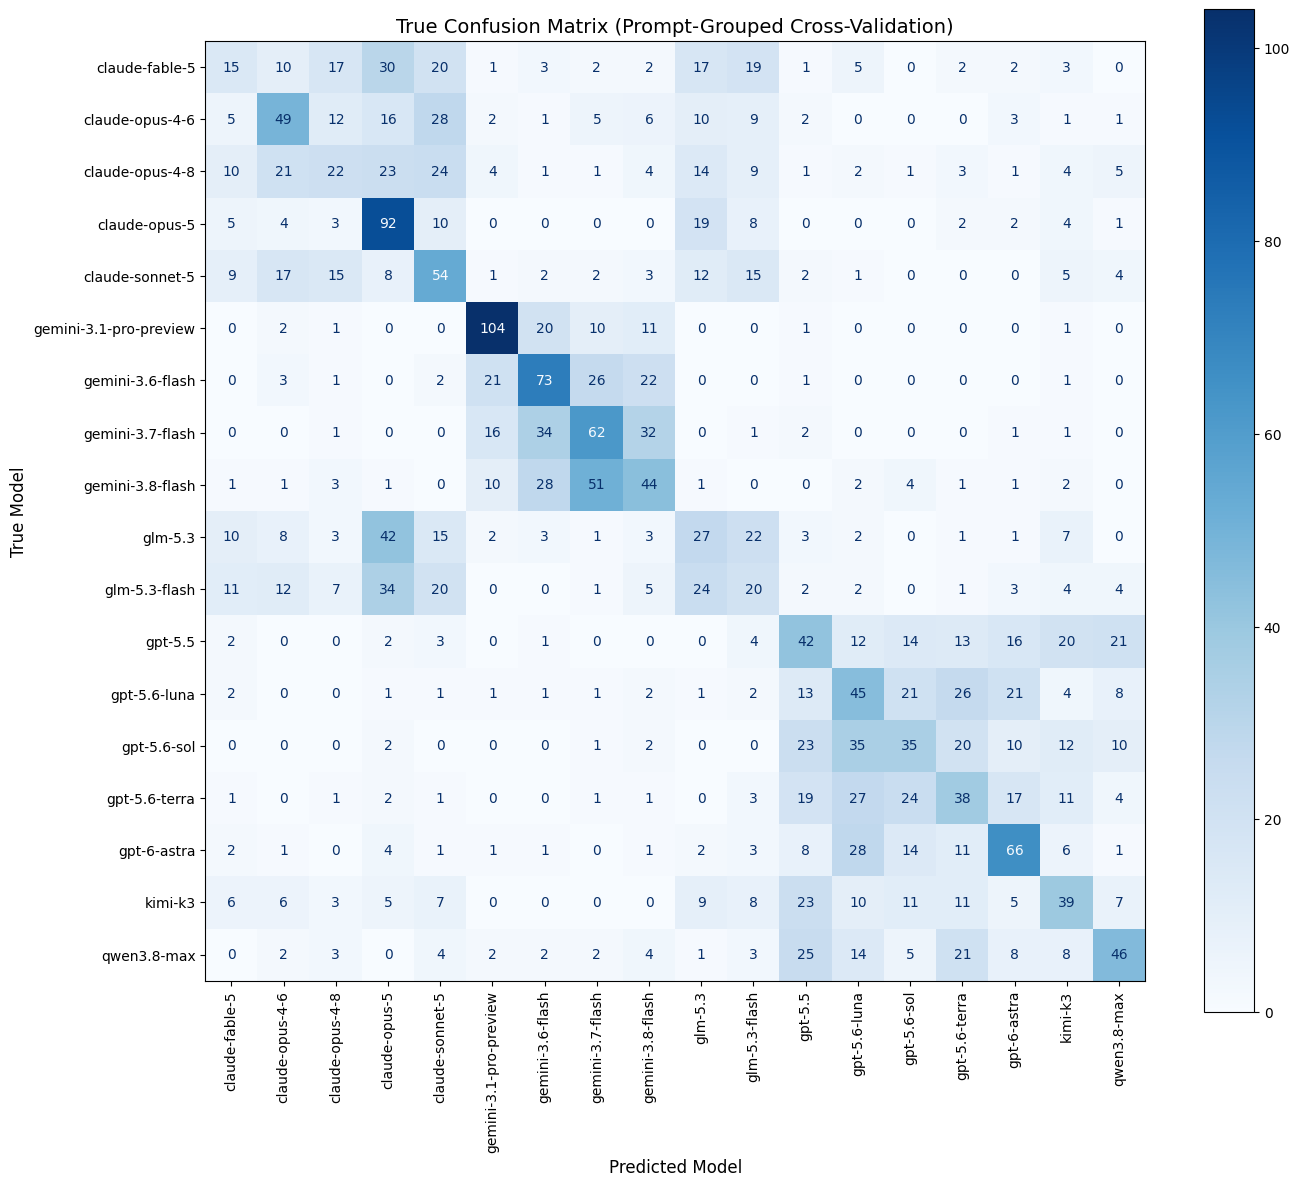

In [14]:
from sklearn.model_selection import StratifiedGroupKFold, cross_val_predict
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# 1. Define the same split per prompt (to prevent data leakage)
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)

# 2. Obtain out-of-fold predictions across the entire train_df
# Each row is predicted by a model that has NOT seen its original prompt during training
y_pred_oof = cross_val_predict(
    final_model, 
    train_df["text"], 
    train_df["model"], 
    groups=train_df["prompt_id"], 
    cv=cv, 
    n_jobs=-1
)

# 3. Calculate the actual confusion matrix
labels = final_model.classes_
cm = confusion_matrix(train_df["model"], y_pred_oof, labels=labels)

# 4. Graphical display
fig, ax = plt.subplots(figsize=(14, 12))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels)
disp.plot(ax=ax, cmap="Blues", xticks_rotation="vertical", colorbar=True)

plt.title("True Confusion Matrix (Prompt-Grouped Cross-Validation)", fontsize=14)
plt.xlabel("Predicted Model", fontsize=12)
plt.ylabel("True Model", fontsize=12)
plt.tight_layout()
plt.show()

### 💡 Interpretation:
* **Model Family Clusters**: Distinct sub-squares form along the diagonal axis, indicating that the model frequently confuses different versions or releases from the same AI lab (e.g., various Claude variants or GPT versions).
* **Cross-Lab Similarities**: Inter-family confusion bridges also emerge (particularly between the GLM and Claude families/ gpt, kimi and qwen families), highlighting stylistic proximities or shared tokenization and phrasing patterns.